# CS4100/CS5100 Data Analysis Lab Worksheet 7: Clustering

Many thanks to Yun Kuen Cheung, Christos Dexiades, Yamuna Krishnamurthy, Nery Riquelme Granada, and Nicolo Colombo for their contributions.

## Intended Learning Outcomes

In this lab session you will:
- learn how to apply the K-Means algorithm to unlabelled datasets using `sklearn.cluster.KMeans`
- learn how to apply the Agglomerative Hierarchical Clustering (AHC) algorithm to unlabelled datasets using `sklearn.cluster.AgglomerativeClustering`
- learn to plot clusters using `matplotlib.pyplot.scatter`.

In [ ]:
# import key packages for data analysis
import numpy as np
import sklearn as sk

---
# K-Means Algorithm

We can apply the K-Means algorithm to an unlabelled dataset using `sklearn.cluster.KMeans`. However, the K-Means algorithm in `sklearn` is very similar to but not exactly the same as the one discussed in the lectures.

The most important parameters of the algorithm are:
1. `n_clusters`: the number of initial clusters --- same as the parameter $K$ we discussed in the lectures;
2. `n_init`: the number of times to run the algorithm on the dataset with different random initial cluster assignments; the best output (the one with the smallest objective function value) among these runs is the final output.

You should also set the `random_state` parameter to be able to reproduce results.

In [ ]:
from sklearn.datasets import load_iris
from sklearn.cluster import KMeans

# Load the dataset
iris = load_iris() # (as_frame=True)
X = iris.data

# apply K-Means to dataset X
kmeans = KMeans(n_clusters=5, n_init=10, random_state=1)
kmeans.fit(X)

# retrieve the final output of cluster assignment
clusters = kmeans.labels_
print(clusters)

In the code snippet above, `kmeans.labels_` gives the final cluster assignment. With this in hand, it is easy to retrieve the indices of observations in each cluster.

In [ ]:
cluster_indices = [[] for j in range(5)]
for i in range(len(clusters)):
    cluster_indices[clusters[i]].append(i)
for j in range(len(cluster_indices)):
    print("The indices in Cluster", j, "are", cluster_indices[j])

We can retrieve the objective function value of the final cluster assignment by `-kmeans.score(X)`.

In [ ]:
print("The objective function value attained by the final cluster assignment is", -kmeans.score(X))

To verify that the value given above is correct, we also compute it ourselves as follows. Recall that the objective function value is the sum of squared distances from each observation to the centroid of its cluster.

The distance from each observation to the centroid of its cluster is computed by `np.linalg.norm(X[j] - centroid)` in the code snippet below.

In [ ]:
objective_function_value = 0.0
for i in range(5):
    cluster = X[cluster_indices[i]]
    centroid = cluster.mean(axis=0)
    for j in cluster_indices[i]:
        objective_function_value += pow(np.linalg.norm(X[j]-centroid), 2.0)
print("The objective function value attained by the final cluster assignment is", objective_function_value)

## Agglomerative Hierarchical Clustering

We can apply the Agglomerative Hierarchical Clustering (AHC) algorithm to an unlabelled dataset using `sklearn.cluster.AgglomerativeClustering`. We can choose "single", "complete", or "average" as linkage function.

In [ ]:
from sklearn.datasets import load_iris
from sklearn.cluster import AgglomerativeClustering as AHC

# Load the dataset
iris = load_iris()
X = iris.data

ahc = AHC(n_clusters=5, linkage="complete")

# compute and retrieve the final output of cluster assignment
clusters = ahc.fit_predict(X)
print(clusters)

Recall that the algorithm is supposed to produce a *dendrogram*, which allows clusters to be computed by dynamically choosing any number of clusters afterwards. However, surprisingly, it is rather clumsy to reuse the dendrogram produced by `sklearn.cluster.AgglomerativeClustering`. (If you are interested; have a look at [this Stack Overflow page](https://stackoverflow.com/questions/36490241/sklearn-agglomerative-clustering-dynamically-updating-the-number-of-clusters).)

As above, we compute the objective function value ourselves. Since we want to look at the objective function values obtained using different linkage functions, it is best to write a function which takes the cluster assignment and outputs the objective function value.

In [ ]:
def objective(clusters, X):
    labels = set(clusters)
    
    cluster_indices = dict()
    for l in labels:
        cluster_indices[l] = []
    
    for i in range(len(clusters)):
        cluster_indices[clusters[i]].append(i)

    objective_function_value = 0
    for l in cluster_indices:
        cluster = X[cluster_indices[l]]
        centroid = cluster.mean(axis=0)
        for i in cluster_indices[l]:
            objective_function_value += pow(np.linalg.norm(X[i]-centroid), 2)

    return objective_function_value

In [ ]:
ahc_complete = AHC(n_clusters=5, compute_full_tree=True, linkage="complete")
clusters_complete = ahc_complete.fit_predict(X)
print("The objective function value by using complete linkage is", objective(clusters_complete, X))

ahc_average = AHC(n_clusters=5, compute_full_tree=True, linkage="average")
clusters_average = ahc_average.fit_predict(X)
print("The objective function value by using average linkage is", objective(clusters_average, X))

ahc_single = AHC(n_clusters=5, compute_full_tree=True, linkage="single")
clusters_single = ahc_single.fit_predict(X)
print("The objective function value by using single linkage is", objective(clusters_single, X))

# Find the two observations that are farthest apart.
pairwise_distances = np.linalg.norm(X[:, None, :] - X[None, :, :], axis=2)
np.fill_diagonal(pairwise_distances, -1)
farthest_pair = np.unravel_index(np.argmax(pairwise_distances), pairwise_distances.shape)
i, j = farthest_pair

print("Farthest observations:", i, "and", j)
print("Coordinates:", X[i], "and", X[j])
print("Distance:", pairwise_distances[i, j])
print("Their single-linkage cluster labels:", clusters_single[i], clusters_single[j])
print("Same cluster:", clusters_single[i] == clusters_single[j])

plt.figure(figsize=(10, 5))
plt.scatter(X[:, 0], X[:, 1], c=clusters_single, cmap="tab10", s=30)
plt.scatter(
    X[[i, j], 0], X[[i, j], 1],
    c="black", marker="x", s=100, linewidths=2,
    label="Farthest pair"
)
plt.xlabel("x")
plt.ylabel("y")
plt.title("Single-linkage clustering with the farthest pair highlighted")
plt.grid(True)
plt.legend()
plt.show()

Note that single linkage yields the worst clusters. As pointed out in the lectures, single linkage tends to produce *biased* cluster assignment, in which one cluster contains many observations, while the other clusters contain very few observations. The large cluster is the main reason behind the high objective function value.

## Plotting Clusters

If the dataset is 2D or 3D, it is fairly easily to visualize the clusters by plotting them. To demonstrate, we first generate a synthetic dataset with 200 observations in $\mathbb{R}^2$, and plot them using `matplotlib.pyplot.scatter`.

In [ ]:
import matplotlib.pyplot as plt

np.random.seed(1)

# observations are randomly generated within [-10,10] x [-10,10]
data = np.random.uniform(-10, 10, size=(200,2))

# then the observations are shifted randomly in one of the three directions specified in shift_choice
shift_direction = [np.array([-20,-10]), np.array([20,-10]), np.array([0,5])]
shift_choice = np.random.randint(0,3,size=200)
for i in range(data.shape[0]):
    data[i] += shift_direction[shift_choice[i]]

# plot the observations in a plane; notice that the observations appear to form three clusters
plt.scatter(data[:,0],data[:,1])
plt.show()

To plot the clusters, we only need the cluster assignment list, which is computed by either K-Means or AHC algorithm. Notice that the clusters produced by the two algorithms are very similar, but the assignments are different for some observations near the boundary between two clusters.

In [ ]:
from sklearn.cluster import KMeans

kmeans = KMeans(n_clusters=3, n_init=10, random_state=1)
kmeans.fit(data)
clusters_kmeans = kmeans.labels_

# retrieve the labels of all clusters
labels_kmeans = set(clusters_kmeans)

# for each label l, we select the observations with label l, and draw a scatter plot:
for l in labels_kmeans:
    plt.scatter(data[clusters_kmeans==l, 0], data[clusters_kmeans==l, 1], label=l)

plt.legend()
plt.show()

In [ ]:
from sklearn.cluster import AgglomerativeClustering as AHC

ahc = AHC(n_clusters=3, linkage="complete")
clusters_ahc = ahc.fit_predict(data)

labels_ahc = set(clusters_ahc)

for l in labels_ahc:
    plt.scatter(data[clusters_ahc==l, 0], data[clusters_ahc==l, 1], label=l)

plt.legend()
plt.show()

## Exercises

You must complete the exercises below during the lab session or your independent study time. Submit your notebook via the module's Moodle page.

**Exercise 1**: Apply the K-Means algorithm to the Iris dataset, for `n_clusters` from 2 to 15, while `n_init` is fixed to be 10. Plot the objective function values against `n_clusters`. What do you observe?

In [ ]:
# K-Means
from sklearn.datasets import load_iris
from sklearn.cluster import KMeans
import numpy as np
import matplotlib.pyplot as plt

# Load the dataset
iris = load_iris() # (as_frame=True)
X = iris.data

# apply K-Means to dataset X
kmeans = KMeans(n_clusters=15, n_init=10, random_state=1)
kmeans.fit(X)

# retrieve the final output of cluster assignment
clusters = kmeans.labels_
print(clusters)

n_clusters_values = range(2, 16)
objective_values_kmeans = []

for k in n_clusters_values:
    kmeans = KMeans(
        n_clusters=k,
        n_init=10,
        random_state=1
    )
    kmeans.fit(X)
    objective_values_kmeans.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(n_clusters_values, objective_values_kmeans, marker="o")
plt.xlabel("n_clusters")
plt.ylabel("Objective function value")
plt.title("K-Means objective function")
plt.xticks(list(n_clusters_values))
plt.grid(True)
plt.show()
plt.savefig('Exercise 1')

Exercise 1: The main observation is that the objective function decreases and evens out with as the number of clusters increases, dropping from 150 to 20 over 15 clusters.

**Exercise 2**: Use the `Iris` dataset in this exercise. Compare the objective function values of the clusters produced by the K-Means algorithm and by the AHC algorithm with complete linkage, for `n_clusters` from 2 to 15. Namely, draw the two objective functions in a single plot. What do you observe?

In [ ]:
# AHC 

ahc = AHC(n_clusters=5, linkage="complete")

# compute and retrieve the final output of cluster assignment
clusters = ahc.fit_predict(X)
print(clusters)

def objective(clusters, X):
    labels = set(clusters)
    
    cluster_indices = dict()
    for l in labels:
        cluster_indices[l] = []
    
    for i in range(len(clusters)):
        cluster_indices[clusters[i]].append(i)

    objective_function_value = 0
    for l in cluster_indices:
        cluster = X[cluster_indices[l]]
        centroid = cluster.mean(axis=0)
        for i in cluster_indices[l]:
            objective_function_value += pow(np.linalg.norm(X[i]-centroid), 2)

    return objective_function_value

objective_values_ahc = []

for k in n_clusters_values:
    ahc_complete = AHC(n_clusters=k, compute_full_tree=True, linkage="complete")
    clusters_complete = ahc_complete.fit_predict(X)
    objective_values_ahc.append(objective(clusters_complete, X))

plt.figure(figsize=(8, 5))
plt.plot(n_clusters_values, objective_values_kmeans, marker="o", label="K-Means")
plt.plot(n_clusters_values, objective_values_ahc, marker="s", label="AHC - complete linkage")
plt.xlabel("n_clusters")
plt.ylabel("Objective function value")
plt.title("K-Means vs AHC objective function")
plt.xticks(list(n_clusters_values))
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.savefig("Exercise 2.png")
plt.show()

The objective function value starts 100 higher on AHC with complete linkage, yet it still converges and decreases as the number of clusters increases, dropping from 250 to 20 over 15 clusters.

**Exercise 3**: This exercise illustrates that the AHC algorithm with single linkage tends to produce bad cluster assignments.

(a) Generate a dataset which contains the following 141 observations in $\mathbb{R}^2$. (i) $(i,0)$ for $i$ from $-50$ to $50$; (ii) 20 observations generated from the uniform distribution in the box $[-10,10]\times[5,10]$; (iii) 20 observations generated from the uniform distribution in the box $[-10,10]\times[-10,-5]$.

(b) Plot the observations. Which two observations are farthest apart?

(c) Apply the AHC algorithm with single linkage to this dataset for `n_clusters = 5`. Observe that the two observations that are farthest apart belong to the same cluster, which sounds bad for any reasonable interpretation of "clustering". Can you explain why this happens?

Dataset shape: (141, 2)


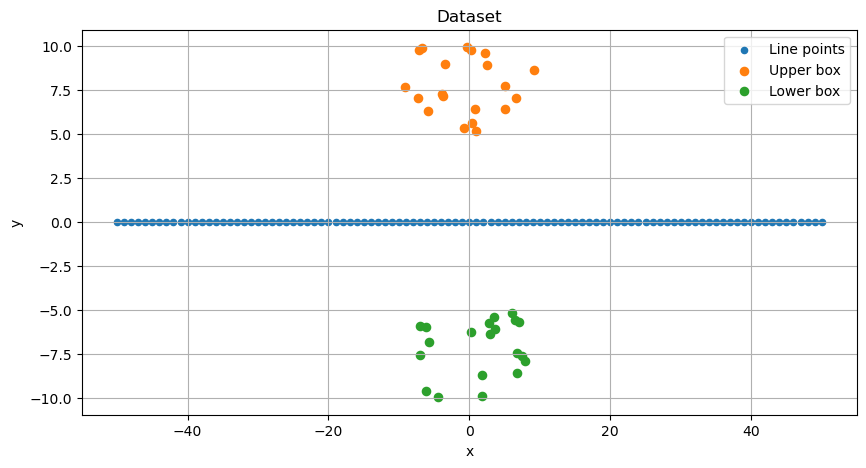

The objective function value by using single linkage is 86167.41567925297


In [61]:
# Generate the 101 observations (i, 0), for i from -50 to 50.
line = np.column_stack((np.arange(-50, 51), np.zeros(101)))

# Generate 20 observations.
rng = np.random.default_rng(1)
upper_box = rng.uniform([-10, 5], [10, 10], size=(20, 2))
lower_box = rng.uniform([-10, -10], [10, -5], size=(20, 2))

# Combine into a 141 x 2 dataset.
X = np.vstack((line, upper_box, lower_box))
print("Dataset shape:", X.shape)

plt.figure(figsize=(10, 5))
plt.scatter(line[:, 0], line[:, 1], label="Line points", s=20)
plt.scatter(upper_box[:, 0], upper_box[:, 1], label="Upper box", s=35)
plt.scatter(lower_box[:, 0], lower_box[:, 1], label="Lower box", s=35)
plt.xlabel("x")
plt.ylabel("y")
plt.title("Dataset")
plt.grid(True)
plt.legend()
plt.show()

ahc_single = AHC(n_clusters=5, compute_full_tree=True, linkage="single")
clusters_single = ahc_single.fit_predict(X)
print("The objective function value by using single linkage is", objective(clusters_single, X))

The two observations furthest apart are marked 1 and 2 in the folder. They both belong to the upper box cluster.
This could happen because the algorithm uses a centroid and each observation is close to that centroid.